# 1. Introduktion och syfte
Syftet med analysen är att undersöka företagets försäljning och identifiera mönster som kan användas som beslutsunderlag inför kommande planeringar. Vi analyserar försäljningen utifrån produktkategorier, geografiska områden, tidsperioder och ordervärden samt undersöker eventuella avvikelser.

### Import av bibliotek och egna moduler
Vi omporterar de Pythonbibliotek och projektets egna moduler som används för databehandling, beräkningar och visualiseringar.

In [2]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt


# 2. Datainläsning och datakontroll
Vi använder datasetet ecommerce_sales.csv, som innehåller information om beställningar, datu, städer, produktkategorier, priser, antal sålda enheter och intäkter.

Inledningsvis läser vi in datamaterialet med Pandas och kontrollerar dess struktur, datatyper och eventuella saknade värden. 

In [3]:
import pandas as pd
df=pd.read_csv("../data/ecommerce_sales.csv")
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [4]:
df.info()
print("\nSaknade värden per kolumn:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 136.8 KB

Saknade värden per kolumn:
order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64


In [5]:
print("Antal rader:", len(df))
print("Antal unika order:", df["order_id"].nunique())

Antal rader: 2500
Antal unika order: 2500


In [6]:
from pathlib import Path
import sys
ROOT=Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))

In [7]:
from src.io_utils import load_data
df=load_data(ROOT/"data"/"ecommerce_sales.csv")
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


# 3. Övergripande nyckeltal
Vi beräknar företagets totala omsättning, antal sålda enheter, antal unika beställningar och genomsnittlig ordervärde (AOV) för att få en övergripande bild av försäljningen. 

In [8]:
import importlib
import src.metrics
importlib.reload(src.metrics)

<module 'src.metrics' from 'C:\\Users\\vafli\\OneDrive\\Desktop\\e-handel -analys\\src\\metrics.py'>

In [9]:
from src.metrics import (
    calc_aov, 
    calc_total_revenue, 
    calc_total_orders, 
    calc_total_units
)

total_intakt=calc_total_revenue(df)
total_antal_salda=calc_total_units(df)
antal_ordrar=calc_total_orders(df)
aov=calc_aov(df)

print(f"Total omsättning: {total_intakt:.0f} kr")
print(f"Antal sålda enheter: {total_antal_salda}")
print(f"Antal beställningar: {antal_ordrar}")
print(f"Genomsnittlig ordervärde (AOV): {aov:.0f} kr")



Total omsättning: 3502767 kr
Antal sålda enheter: 7463
Antal beställningar: 2500
Genomsnittlig ordervärde (AOV): 1401 kr


# 4. Vad säljer vi?
Vi analyserar vilka produktkategorier som genererar störst omsättning och jämför försäljningsvolymen mellan kategorierna. Vi undersöker även genomsnittlig intäkt per såld enhet och indentifierar de tre största kategorierna efter omsättning.


In [10]:
import importlib
import src.metrics

importlib.reload(src.metrics)

from src.metrics import revenue_by_category

intakter_per_kategori=revenue_by_category(df)

print(intakter_per_kategori.map(lambda x: f"{x:,.0f}".replace("," , " ")))

category
Electronics    1 364 228
Sports           734 653
Clothing         586 745
Home             511 071
Beauty           163 054
Toys             143 016
Name: revenue, dtype: str


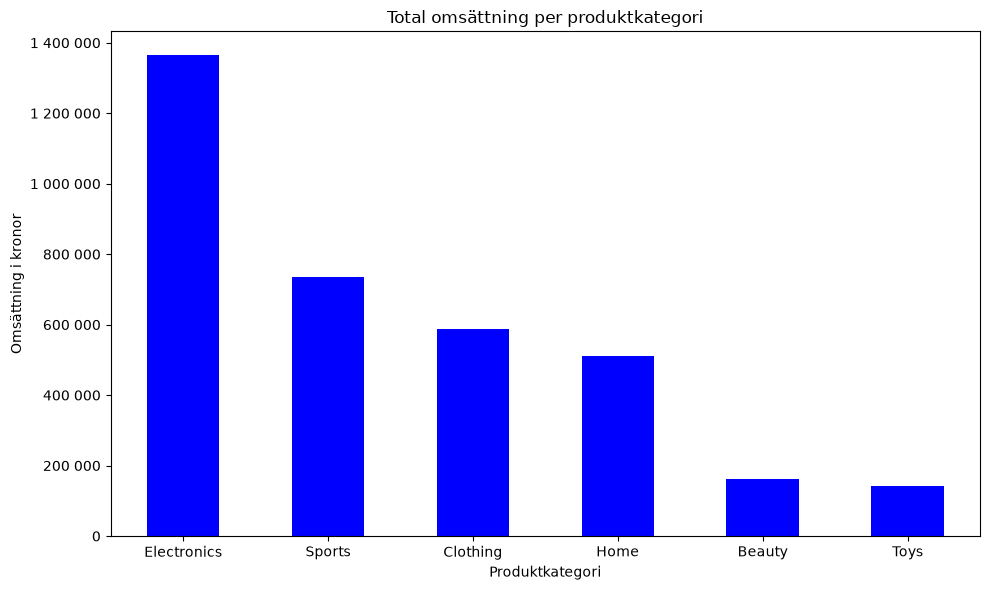

In [11]:
import matplotlib
import src.viz

importlib.reload(src.viz)

from src.viz import plot_revenue_by_category

plot_revenue_by_category(intakter_per_kategori)

In [12]:
import importlib
import src.metrics

importlib.reload(src.metrics)

from src.metrics import units_by_category

enheter_per_kategori=units_by_category(df)

print(enheter_per_kategori)

category
Electronics    1753
Clothing       1655
Sports         1401
Home           1278
Toys            717
Beauty          659
Name: units, dtype: int64


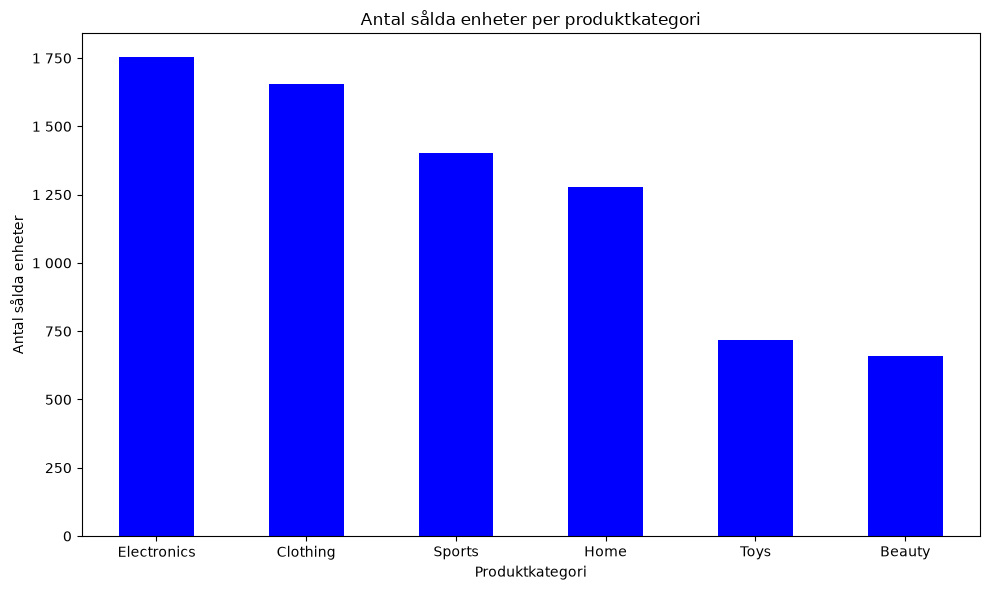

In [13]:
import importlib
import src.viz

importlib.reload(src.viz)

from src.viz import plot_units_by_category

plot_units_by_category(enheter_per_kategori)

In [14]:
import importlib
import src.metrics

importlib.reload(src.metrics)

from src.metrics import revenue_per_unit_by_category

intakt_per_enhet = revenue_per_unit_by_category(df)

print(intakt_per_enhet.map(lambda x: f"{x:,.0f}".replace("," , " ")))

category
Electronics    778
Sports         524
Home           400
Clothing       355
Beauty         247
Toys           199
dtype: str


In [15]:
andel_omsattning = (
    intakter_per_kategori/ calc_total_revenue(df)*100
    ).round(1)

andel_enheter = (
    enheter_per_kategori / calc_total_units(df)*100
).round(1)

print("Andel av total omsättning (%):")
display(andel_omsattning)

print("Andel av totalt sålda enheter (%):")
display(andel_enheter)

Andel av total omsättning (%):


category
Electronics    38.9
Sports         21.0
Clothing       16.8
Home           14.6
Beauty          4.7
Toys            4.1
Name: revenue, dtype: float64

Andel av totalt sålda enheter (%):


category
Electronics    23.5
Clothing       22.2
Sports         18.8
Home           17.1
Toys            9.6
Beauty          8.8
Name: units, dtype: float64

In [16]:
import pandas as pd

tabell=pd.DataFrame(
    {"Sålda enheter": enheter_per_kategori,
     "Intäkt per enhet (kr)": intakt_per_enhet
     })
tabell=tabell.sort_values(by="Sålda enheter",ascending=False)
display(tabell.style.format({
    "Sålda enheter": "{:,.0f}",
    "Intäkt per enhet (kr)": "{:,.0f}"},thousands=" "))


,Sålda enheter,Intäkt per enhet (kr)
category,,
Electronics,1 753,778
Clothing,1 655,355
Sports,1 401,524
Home,1 278,400
Toys,717,199
Beauty,659,247


### 4.1 Sammanfattning/Slutsats-Vad säljer vi?

Electronics är den ledande produktkategprin med cirka 39% av den totala omsättningen och cirka 24% av sålda enheter. Kategorin har även högst genomsnittlig intäkt per såld enhet, cirka 778 kr. 

Clothing har högre försäljningsvolym än Sports, men Sports genererar både högre total omsättning och högre genomsnittlig intäkt per såld enhet. 

Resultatet visar att både försäljningsvolym och genomsnittlig intäkt per enhet är viktiga för att förstå vilka kategorier som bidrar mest till omsättningen.

Rekommendation: 

Sports och Electronics är intressanta kategorier att prioritera inför kommande satsningar. Men för att avgöra lönsamma satsningar behöver vi även vet kostnader och vinstmarginaler. Innan man gör några stora satsninsgar på produktkategorierna Toys och Beaty, kan det vara värt att göra en fördjupad lönsamhetsanalys. Den bör omfatta både direkta kostnader och resursåtgång, exempelvis lagerhållning och arbetskraft. Utifrån resultaten kan vi bedöma om det är mer fördelaktigt att satsa på ökad försäljning eller överväga att avveckla någon av kategorierna.


# 5. Var säljer vi?



In [17]:
import importlib
import src.metrics

importlib.reload(src.metrics)

from src.metrics import revenue_by_city

intakter_per_stad=revenue_by_city(df)

display(intakter_per_stad)

city
Stockholm    1227201.94
Göteborg      859019.65
Malmö         567926.32
Uppsala       551478.42
Västerås      297140.90
Name: revenue, dtype: float64

In [18]:
andel_per_stad=(intakter_per_stad/calc_total_revenue(df)*100
).round(1)

display(andel_per_stad)

city
Stockholm    35.0
Göteborg     24.5
Malmö        16.2
Uppsala      15.7
Västerås      8.5
Name: revenue, dtype: float64

In [19]:
tabell_stader=pd.DataFrame({
    "Omsättning (kr)": intakter_per_stad,
    "Andel av omsättning (%)": andel_per_stad
})

display(
    tabell_stader.style.format({
      "Omsättning (kr)": "{:,.0f}",
      "Andel av omsättningen (%)": "{:,.1f}"
    }, thousands=" ")
)

,Omsättning (kr),Andel av omsättning (%)
city,,
Stockholm,1 227 202,35.000000
Göteborg,859 020,24.500000
Malmö,567 926,16.200000
Uppsala,551 478,15.700000
Västerås,297 141,8.500000


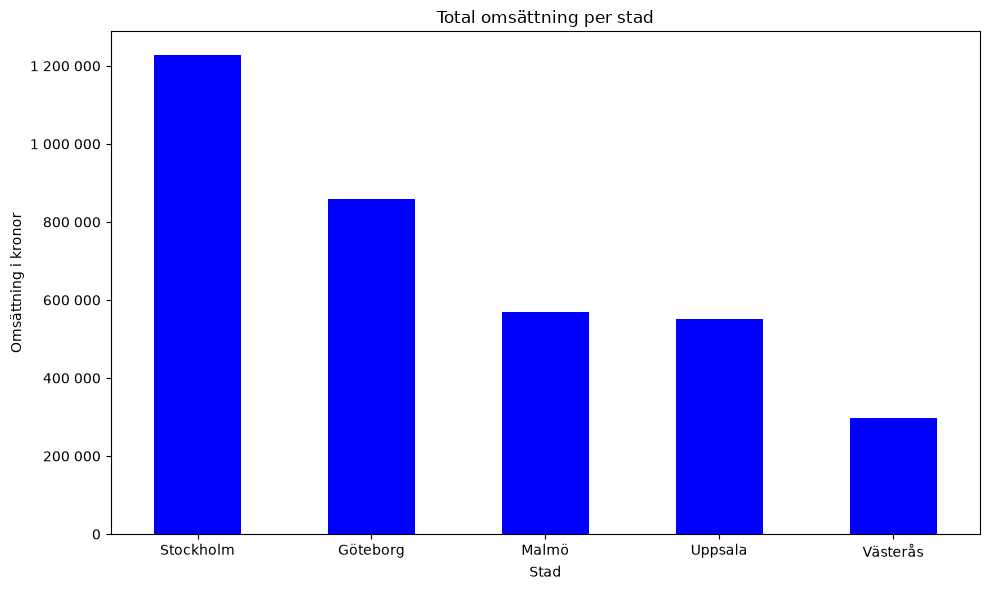

In [20]:
import importlib
import src.viz

importlib.reload(src.viz)

from src.viz import plot_revenue_by_city

plot_revenue_by_city(intakter_per_stad)



### 5.1 Sammanfattning och slutsats – Var säljer vi?

Stockholm står för störst andel av omsättningen (35 %), följt av Göteborg (24,5 %). Tillsammans står de för nästan 60 % av företagets totala omsättning. Malmö och Uppsala ligger relativt nära varandra, medan Västerås har lägst omsättning (8,5 %).

Skillnaderna kan bero på flera faktorer, exempelvis befolkningsstorlek, antal beställningar, kundernas köpbeteende, produktutbud, konkurrens, marknadsföring och leveransmöjligheter. En högre omsättning behöver därför inte betyda att företaget presterar bättre på den marknaden.

**Rekommendation**

Innan företaget bestämmer var framtida satsningar ska göras bör omsättningen jämföras med städernas befolkningsstorlek. Företaget bör även undersöka antal beställningar, genomsnittligt ordervärde, kundernas köpmönster, marknadsföring samt kostnader och vinstmarginaler per stad. Det ger ett bättre underlag för att identifiera marknader med störst potential för lönsam tillväxt.

# 6. När säljer vi?- Månadsanalys januari-juni 2024

Månadsanalysen syftar till att undersöka **försäljningsutvecklingen** under första halvåret 2024 och identifiera eventuella förändringar och avvikelser.

Analysen utgår från den totala omsättningen och dess fördelning mellan produktkategorier och städer. Därefter fördjupas analysen med hjälp av nyckeltal som försäljningsvolym, antal order och genomsnittligt ordervärde.

In [21]:
df_manad = df.copy()
df_manad["date"] = pd.to_datetime(df_manad["date"])
df_manad["månad"] = df_manad["date"].dt.month

In [22]:
import importlib
import src.metrics

importlib.reload(src.metrics)

from src.metrics import månadsförsäljning

omsattning_manad = månadsförsäljning(df_manad)

display(omsattning_manad)

månad
1    664083.32
2    548462.03
3    487602.00
4    580194.83
5    632165.16
6    590259.89
Name: revenue, dtype: float64

In [23]:
from src.metrics import månadsförsäljning_kategori

omsattning_kategori = månadsförsäljning_kategori(df_manad)


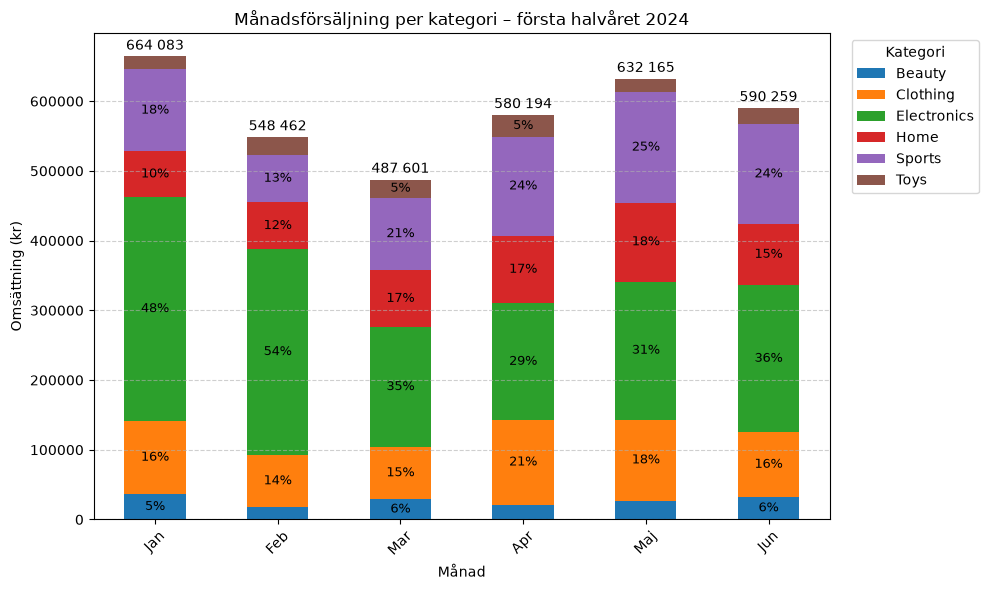

In [24]:
import importlib
import src.viz

importlib.reload(src.viz)

from src.viz import visa_manadsforsaljning_kategori

visa_manadsforsaljning_kategori(omsattning_kategori)

**Figur 1. Månadsomsättning per produktkategori, januari–juni 2024.**

Omsättningen minskade från januari till mars, med den största nedgången mellan januari och februari (−17,4 %). Mellan februari och mars minskade omsättningen ytterligare med 11,1 %, samtidigt som Electronics andel sjönk från cirka 54 % till 35 %.

Under april och maj återhämtade sig omsättningen, innan den minskade något igen i juni.

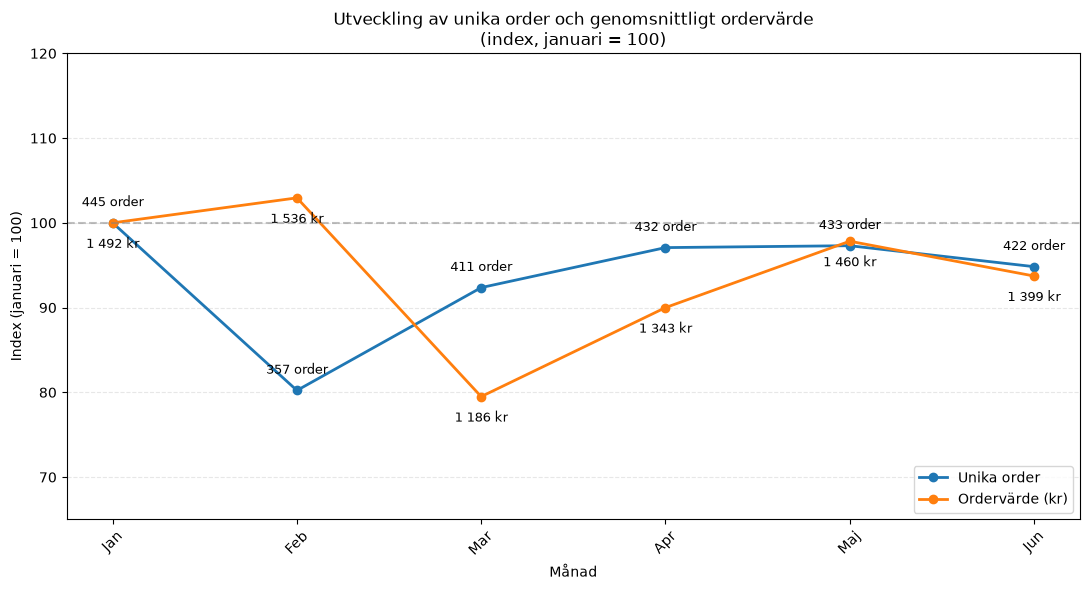

In [25]:
import importlib
import src.viz

importlib.reload(src.viz)


from src.metrics import (
    antal_unika_order_månad,
    ordervärde_medel_månad
)

antal_order = antal_unika_order_månad(df_manad)
ordervarde = ordervärde_medel_månad(df_manad)

from src.viz import visa_orderutveckling_index

visa_orderutveckling_index(antal_order, ordervarde)

**Figur 2. Utveckling av antal beställningar och genomsnittligt ordervärde, januari–juni 2024 (index, januari = 100).**

Mellan januari och februari minskade antalet beställningar med cirka 20 %, medan det genomsnittliga ordervärdet var relativt stabilt.

Mellan februari och mars ökade däremot antalet beställningar med cirka 15 %, samtidigt som det genomsnittliga ordervärdet sjönk med cirka 23 %.

Det visar att omsättningsnedgångarna sammanfaller med två olika försäljningsmönster: först färre beställningar och därefter ett lägre genomsnittligt ordervärde.

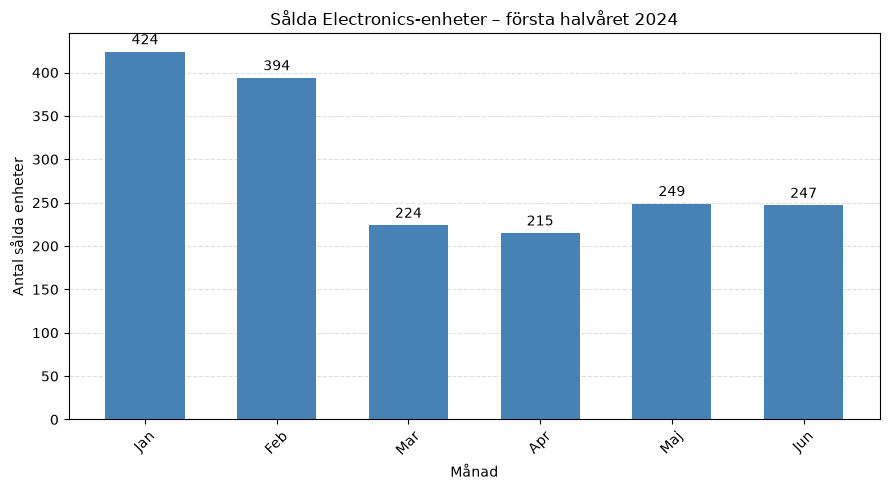

In [26]:
from src.metrics import antal_electronics_manad
from src.viz import visa_electronics_enheter_manad

electronics_enheter = antal_electronics_manad(df_manad)

visa_electronics_enheter_manad(electronics_enheter)

**Figur 3. Antal sålda Electronics-enheter per månad, januari–juni 2024.**

Antalet sålda Electronics-enheter minskade från 394 i februari till 224 i mars, en nedgång på cirka 43 %. Försäljningen låg därefter kvar på en betydligt lägre nivå under resten av halvåret.

Eftersom Electronics har högst genomsnittlig intäkt per såld enhet kan nedgången ha bidragit till det lägre genomsnittliga ordervärdet i mars.

### 6.1 Sammanfattning och slutsats – När säljer vi?

Omsättningen minskade från januari till mars, men återhämtade sig under april och maj innan den sjönk något igen i juni.

Mellan januari och februari minskade antalet beställningar med cirka 20 %, medan det genomsnittliga ordervärdet var relativt stabilt. Mellan februari och mars ökade däremot antalet beställningar med cirka 15 %, samtidigt som det genomsnittliga ordervärdet sjönk med cirka 23 %.

En möjlig bidragande faktor är Electronics, där antalet sålda enheter minskade med cirka 43 % mellan februari och mars. Försäljningsvolymen inom kategorin låg kvar på en betydligt lägre nivå under resten av halvåret, trots att företagets totala omsättning återhämtade sig.

**Rekommendation**

Företaget bör undersöka varför Electronics-försäljningen minskade, exempelvis genom att analysera efterfrågan, produktutbud, kampanjer och lagerstatus. Det är också viktigt att följa både antalet beställningar och det genomsnittliga ordervärdet för att förstå vad som driver förändringar i omsättningen.

# 7. Hur ser en typisk order ut?

Vi undersöker det genomsnittliga ordervärdet, medianen och hur mycket ordervärdena varierar. Syftet är att få en bättre bild av kundernas köpbeteende och identifiera eventuella ovanligt stora beställningar.

In [27]:
import importlib
import src.metrics

importlib.reload(src.metrics)

from src.metrics import order_statistics

order_statistik = order_statistics(df)

display(order_statistik)

count    2500.00
mean     1401.11
std      1166.94
min        50.00
25%       577.96
50%      1088.69
75%      1884.75
max      9192.60
Name: revenue, dtype: float64

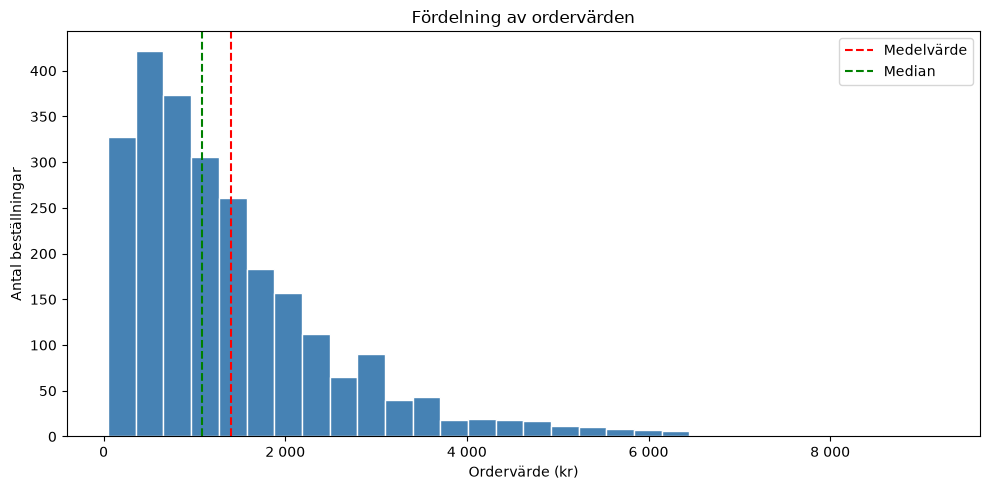

In [28]:
import importlib
import src.viz

importlib.reload(src.viz)

from src.viz import plot_order_distribution

plot_order_distribution(df)

### 7.1 Sammanfattning och slutsats – Hur ser en typisk order ut?

Det genomsnittliga ordervärdet är cirka 1 401 kr, medan medianen ligger på cirka 1 089 kr. Skillnaden visar att större beställningar drar upp genomsnittet och att fördelningen är högerskev.

Hälften av beställningarna har ett värde mellan cirka 578 och 1 885 kr. Samtidigt finns det enstaka betydligt större beställningar, med ett högsta ordervärde på cirka 9 193 kr.

Medianen ger därför en bättre bild av en typisk beställning än medelvärdet.

**Rekommendation**

Företaget bör följa både median och genomsnittligt ordervärde för att få en mer rättvisande bild av kundernas köpbeteende. Det kan även vara värdefullt att undersöka de största beställningarna närmare för att förstå vilka produkter och kundbeteenden som ligger bakom dem.

# 8. Eventuella avvikelser
Vi undersöker om det finns ovanligt stora eller små beställningar och vilka förändringar i försäljningen som sticker ut.

In [29]:
import importlib
import src.metrics

importlib.reload(src.metrics)

from src.metrics import order_outliers

avvikande_order = order_outliers(df)

print("Antal avvikande beställningar:", len(avvikande_order))

print("\nDe fem största avvikande beställningarna:")
display(avvikande_order.head(5))

Antal avvikande beställningar: 111

De fem största avvikande beställningarna:


order_id
101411    9192.60
101339    8516.85
101491    8370.12
101733    7366.38
101518    7018.45
Name: revenue, dtype: float64

In [30]:
andel_avvikande = (
    avvikande_order.sum() / calc_total_revenue(df) * 100
)

print(f"Avvikande order står för {andel_avvikande:.1f} % av omsättningen.")

Avvikande order står för 15.9 % av omsättningen.


### 8.1 Sammanfattning och slutsats – Avvikelser

Med hjälp av IQR-metoden (en statistisk metod som identifierar ovanligt höga eller låga värden utifrån kvartilavståndet) identifierades 111 statistiskt avvikande beställningar, motsvarande 4,4 % av samtliga order. Dessa står tillsammans för 15,9 % av företagets totala omsättning.

Resultatet visar att ett relativt litet antal stora beställningar bidrar med en betydande del av omsättningen. Det hjälper också till att förklara varför det genomsnittliga ordervärdet är högre än medianen.

**Rekommendation**

Företaget bör undersöka vilka produkter och köpmönster som kännetecknar de större beställningarna. Det kan ge värdefull information om möjligheter att öka ordervärdet. Samtidigt bör dessa beställningar inte automatiskt betraktas som felaktiga bara för att de är statistiskt avvikande.

# 9. Sammanfattning och rekommendationer


### Sammanfattning

Analysen omfattar 2 500 beställningar under januari–juni 2024, med en total omsättning på cirka 3,5 miljoner kronor.

**Electronics är företagets största produktkategori** och står för cirka 39 % av omsättningen. Stockholm och Göteborg är de största försäljningsmarknaderna och står tillsammans för cirka 60 % av den totala omsättningen.

Försäljningen minskade under årets första tre månader men återhämtade sig under april och maj. Nedgången i mars sammanföll med ett lägre genomsnittligt ordervärde och en kraftig minskning av antalet sålda Electronics-enheter.

En typisk beställning har ett ordervärde på cirka 1 089 kr (median), medan genomsnittet ligger på 1 401 kr. Analysen visar också att 4,4 % av beställningarna står för 15,9 % av omsättningen, vilket visar att större beställningar har en betydande påverkan på resultatet.

### Rekommendationer

**1. Undersök utvecklingen inom Electronics och Sports**

Electronics och Sports står för en stor del av företagets omsättning. Företaget bör särskilt undersöka varför Electronics-försäljningen minskade kraftigt under våren och om förändringen beror på efterfrågan, sortiment, kampanjer eller lagerstatus. Innan nya satsningar görs behöver även kostnader och vinstmarginaler analyseras.

**2. Analysera försäljningen i relation till marknadens storlek**

Stockholm och Göteborg genererar störst omsättning, men det behöver inte innebära att efterfrågan per invånare är högst där. Företaget bör jämföra försäljningen med befolkningsunderlag och undersöka antal beställningar, genomsnittligt ordervärde och kundunderlag per stad. Det ger en bättre grund för att bedöma vilka marknader som har störst utvecklingspotential.

**3. Följ ordervärden och undersök större beställningar**

Företaget bör följa både median och genomsnittligt ordervärde för att förstå kundernas köpbeteende. Eftersom en liten andel stora beställningar står för en betydande del av omsättningen kan det vara värdefullt att undersöka vilka produkter och köpmönster som kännetecknar dessa beställningar och om det finns möjligheter att öka ordervärdet.